In [ ]:
# Task 28: Outlier Detection

## Objective
Create a box plot for a numerical variable and identify
potential outliers in the dataset.

## Deliverables
- Employee salary dataset
- Box plot visualization
- Identified potential outliers
- IQR-based outlier analysis
- Statistical summary
- Explanation of findings

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Create employee salary dataset

salaries = [
    35000, 38000, 40000, 42000, 43000,
    45000, 46000, 48000, 50000, 52000,
    54000, 55000, 56000, 58000, 60000,
    62000, 65000, 68000, 70000, 72000,
    75000, 78000, 80000, 85000, 90000,
    95000, 100000, 105000, 110000, 350000
]

departments = [
    "IT", "HR", "Finance", "Operations", "IT",
    "HR", "Finance", "Operations", "IT", "HR",
    "Finance", "Operations", "IT", "HR", "Finance",
    "Operations", "IT", "HR", "Finance", "Operations",
    "IT", "HR", "Finance", "Operations", "IT",
    "HR", "Finance", "Operations", "IT", "Management"
]

employee_ids = [
    f"EMP{i:03d}" for i in range(1, 31)
]

df = pd.DataFrame({
    "employee_id": employee_ids,
    "department": departments,
    "monthly_salary_inr": salaries
})

print("Employee salary dataset created successfully!")
print("Total employees:", len(df))

display(df.head(10))

Employee salary dataset created successfully!
Total employees: 30


,employee_id,department,monthly_salary_inr
0,EMP001,IT,35000
1,EMP002,HR,38000
2,EMP003,Finance,40000
3,EMP004,Operations,42000
4,EMP005,IT,43000
5,EMP006,HR,45000
6,EMP007,Finance,46000
7,EMP008,Operations,48000
8,EMP009,IT,50000
9,EMP010,HR,52000


In [ ]:
# Save the original dataset
df.to_csv(
    "employee_salary_data.csv",
    index=False
)

# Load the CSV file
df = pd.read_csv("employee_salary_data.csv")

print("Employee dataset loaded successfully!")

display(df)

Employee dataset loaded successfully!


,employee_id,department,monthly_salary_inr
0,EMP001,IT,35000
1,EMP002,HR,38000
2,EMP003,Finance,40000
3,EMP004,Operations,42000
4,EMP005,IT,43000
5,EMP006,HR,45000
6,EMP007,Finance,46000
7,EMP008,Operations,48000
8,EMP009,IT,50000
9,EMP010,HR,52000


In [ ]:
print("DATASET INFORMATION")

print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

DATASET INFORMATION
Total records: 30
Total columns: 3

Column names:
['employee_id', 'department', 'monthly_salary_inr']

Data types:
employee_id           object
department            object
monthly_salary_inr     int64
dtype: object

First five records:


,employee_id,department,monthly_salary_inr
0,EMP001,IT,35000
1,EMP002,HR,38000
2,EMP003,Finance,40000
3,EMP004,Operations,42000
4,EMP005,IT,43000



Last five records:


,employee_id,department,monthly_salary_inr
25,EMP026,HR,95000
26,EMP027,Finance,100000
27,EMP028,Operations,105000
28,EMP029,IT,110000
29,EMP030,Management,350000


In [ ]:
print("EMPLOYEE SALARY STATISTICAL SUMMARY")

display(
    df["monthly_salary_inr"].describe()
)

EMPLOYEE SALARY STATISTICAL SUMMARY


,monthly_salary_inr
count,30.000000
mean,74233.333333
std,56052.735842
min,35000.000000
25%,48500.000000
50%,61000.000000
75%,79500.000000
max,350000.000000


In [ ]:
salary = df["monthly_salary_inr"]

# Calculate quartiles
Q1 = salary.quantile(0.25)
Q2 = salary.quantile(0.50)
Q3 = salary.quantile(0.75)

# Calculate interquartile range
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_boundary = Q1 - (1.5 * IQR)
upper_boundary = Q3 + (1.5 * IQR)

print("=" * 55)
print("           IQR OUTLIER DETECTION ANALYSIS")
print("=" * 55)

print(f"First Quartile (Q1): ₹{Q1:,.2f}")
print(f"Median (Q2): ₹{Q2:,.2f}")
print(f"Third Quartile (Q3): ₹{Q3:,.2f}")
print(f"Interquartile Range: ₹{IQR:,.2f}")

print(f"Lower Boundary: ₹{lower_boundary:,.2f}")
print(f"Upper Boundary: ₹{upper_boundary:,.2f}")

           IQR OUTLIER DETECTION ANALYSIS
First Quartile (Q1): ₹48,500.00
Median (Q2): ₹61,000.00
Third Quartile (Q3): ₹79,500.00
Interquartile Range: ₹31,000.00
Lower Boundary: ₹2,000.00
Upper Boundary: ₹126,000.00


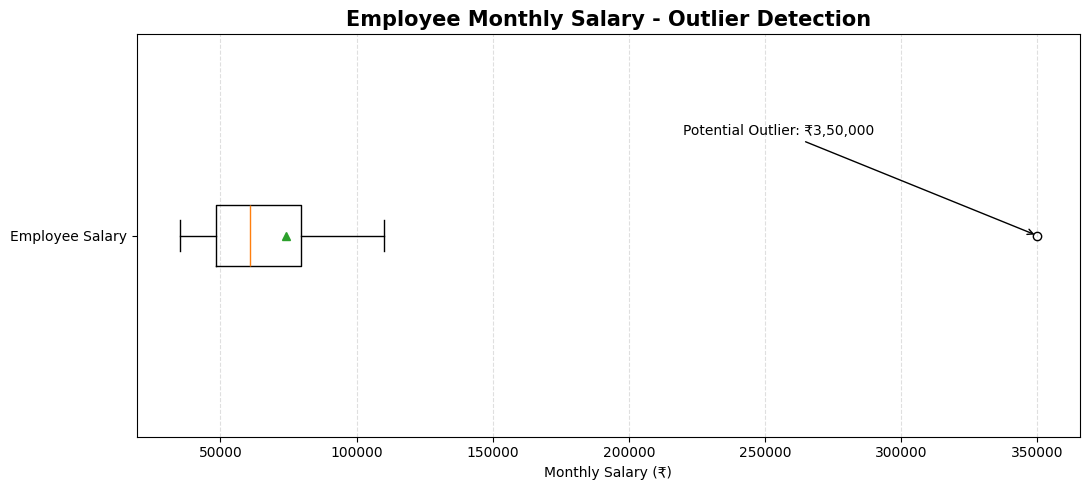

In [7]:
# Create charts folder
Path("charts").mkdir(exist_ok=True)

plt.figure(figsize=(11, 5))

plt.boxplot(
    salary,
    vert=False,
    showmeans=True,
    showfliers=True
)

plt.title(
    "Employee Monthly Salary - Outlier Detection",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Monthly Salary (₹)")
plt.yticks([1], ["Employee Salary"])

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.annotate(
    "Potential Outlier: ₹3,50,000",
    xy=(350000, 1),
    xytext=(220000, 1.25),
    arrowprops={"arrowstyle": "->"}
)

plt.tight_layout()

plt.savefig(
    "charts/employee_salary_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# Identify values below or above IQR boundaries

outlier_condition = (
    (salary < lower_boundary) |
    (salary > upper_boundary)
)

outliers = df.loc[outlier_condition].copy()

print("POTENTIAL OUTLIER RECORDS")

display(outliers)

print("\nTotal potential outliers:", len(outliers))

POTENTIAL OUTLIER RECORDS


,employee_id,department,monthly_salary_inr
29,EMP030,Management,350000



Total potential outliers: 1


In [9]:
lower_outliers = df[
    df["monthly_salary_inr"] < lower_boundary
]

upper_outliers = df[
    df["monthly_salary_inr"] > upper_boundary
]

print("LOWER OUTLIERS")
display(lower_outliers)

print("UPPER OUTLIERS")
display(upper_outliers)

print("Lower outlier count:", len(lower_outliers))
print("Upper outlier count:", len(upper_outliers))

LOWER OUTLIERS


,employee_id,department,monthly_salary_inr


UPPER OUTLIERS


,employee_id,department,monthly_salary_inr
29,EMP030,Management,350000


Lower outlier count: 0
Upper outlier count: 1


In [10]:
outlier_summary = pd.DataFrame({
    "Metric": [
        "Total employees",
        "Minimum salary",
        "Maximum salary",
        "Mean salary",
        "Median salary",
        "First quartile (Q1)",
        "Third quartile (Q3)",
        "Interquartile range (IQR)",
        "Lower boundary",
        "Upper boundary",
        "Lower outlier count",
        "Upper outlier count",
        "Total potential outliers"
    ],

    "Value": [
        len(df),
        salary.min(),
        salary.max(),
        round(salary.mean(), 2),
        salary.median(),
        Q1,
        Q3,
        IQR,
        lower_boundary,
        upper_boundary,
        len(lower_outliers),
        len(upper_outliers),
        len(outliers)
    ]
})

print("FINAL OUTLIER ANALYSIS SUMMARY")

display(outlier_summary)

FINAL OUTLIER ANALYSIS SUMMARY


,Metric,Value
0,Total employees,30.00
1,Minimum salary,35000.00
2,Maximum salary,350000.00
3,Mean salary,74233.33
4,Median salary,61000.00
5,First quartile (Q1),48500.00
6,Third quartile (Q3),79500.00
7,Interquartile range (IQR),31000.00
8,Lower boundary,2000.00
9,Upper boundary,126000.00


In [11]:
print("FINAL DATASET VERIFICATION")

print("Original employee records:", len(df))
print("Potential outliers identified:", len(outliers))

print("Records retained:", len(df))

print(
    "\nPotential outlier employee IDs:",
    outliers["employee_id"].tolist()
)

print("\nOriginal dataset has been preserved.")

FINAL DATASET VERIFICATION
Original employee records: 30
Potential outliers identified: 1
Records retained: 30

Potential outlier employee IDs: ['EMP030']

Original dataset has been preserved.


In [12]:
# Save original dataset
df.to_csv(
    "employee_salary_data.csv",
    index=False
)

# Save detected outlier records
outliers.to_csv(
    "outlier_results.csv",
    index=False
)

# Save statistical summary
outlier_summary.to_csv(
    "outlier_summary.csv",
    index=False
)

print("All project CSV files exported successfully!")

All project CSV files exported successfully!


In [13]:
from google.colab import files

files.download("employee_salary_data.csv")
files.download("outlier_results.csv")
files.download("outlier_summary.csv")
files.download("charts/employee_salary_boxplot.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>